In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

def load_data(filename):
    data = pd.read_csv(
        filename,
        header=None,
        names=columns,
        skipinitialspace=True,
        comment="|"
    )

    # Удаляем пробелы и обрабатываем неизвестные значения
    for column in data.select_dtypes(include="object").columns:
        data[column] = data[column].str.strip()

    data.replace("?", np.nan, inplace=True)
    data.dropna(inplace=True)

    # В тестовом файле метки дохода заканчиваются точкой
    data["income"] = data["income"].str.replace(
        ".", "", regex=False
    )

    return data


train_data = load_data("adult.data.txt")
test_data = load_data("adult.test.txt")

print("Размер обучающей выборки:", train_data.shape)
print("Размер тестовой выборки:", test_data.shape)

display(train_data.head()) 
X_train = train_data.drop(columns=["income"])
y_train = train_data["income"]

X_test = test_data.drop(columns=["income"])
y_test = test_data["income"]

numeric_features = [
    "age", "fnlwgt", "education_num",
    "capital_gain", "capital_loss", "hours_per_week"
]

categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features
]

preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    ("numeric", "passthrough", numeric_features)
])

print("Количество признаков:", X_train.shape[1])
print("Классы дохода:", y_train.unique())

C:\Users\1661322\AppData\Local\Temp\ipykernel_4820\1737050261.py:38: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in data.select_dtypes(include="object").columns:
C:\Users\1661322\AppData\Local\Temp\ipykernel_4820\1737050261.py:38: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/us

Размер обучающей выборки: (30162, 15)
Размер тестовой выборки: (15060, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Количество признаков: 14
Классы дохода: <StringArray>
['<=50K', '>50K']
Length: 2, dtype: str


In [4]:
# Создаём конвейер предобработки и классификации
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Обучаем модель
start_time = time.time()

tree_model.fit(X_train, y_train)

tree_time = time.time() - start_time

# Получаем предсказания
tree_predictions = tree_model.predict(X_test)

# Рассчитываем показатели качества
tree_accuracy = accuracy_score(y_test, tree_predictions)

tree_precision = precision_score(
    y_test, tree_predictions,
    pos_label=">50K"
)

tree_recall = recall_score(
    y_test, tree_predictions,
    pos_label=">50K"
)

tree_f1 = f1_score(
    y_test, tree_predictions,
    pos_label=">50K"
)

print("Результаты одиночного дерева решений")
print("-" * 40)
print(f"Accuracy:  {tree_accuracy:.4f} ({tree_accuracy * 100:.2f}%)")
print(f"Precision: {tree_precision:.4f} ({tree_precision * 100:.2f}%)")
print(f"Recall:    {tree_recall:.4f} ({tree_recall * 100:.2f}%)")
print(f"F1-score:  {tree_f1:.4f} ({tree_f1 * 100:.2f}%)")
print(f"Время обучения: {tree_time:.2f} сек.")

Результаты одиночного дерева решений
----------------------------------------
Accuracy:  0.8044 (80.44%)
Precision: 0.5988 (59.88%)
Recall:    0.6181 (61.81%)
F1-score:  0.6083 (60.83%)
Время обучения: 1.70 сек.


In [6]:
n_estimators_list = [50, 60, 70, 80, 90, 100]

results = []

for n_estimators in n_estimators_list:
    print(f"Обучение случайного леса: {n_estimators} деревьев...")

    start_time = time.time()

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=n_estimators,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    elapsed_time = time.time() - start_time

    results.append({
        "Количество деревьев": n_estimators,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label=">50K"
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label=">50K"
        ),
        "F1-score": f1_score(
            y_test, predictions, pos_label=">50K"
        ),
        "Время, сек.": elapsed_time
    })

results_df = pd.DataFrame(results)

# Представим показатели качества в процентах
display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}",
        "Время, сек.": "{:.2f}"
    })
)

Обучение случайного леса: 50 деревьев...
Обучение случайного леса: 60 деревьев...
Обучение случайного леса: 70 деревьев...
Обучение случайного леса: 80 деревьев...
Обучение случайного леса: 90 деревьев...
Обучение случайного леса: 100 деревьев...


,Количество деревьев,Accuracy,Precision,Recall,F1-score,"Время, сек."
0,50,84.52%,71.52%,61.49%,66.12%,3.63
1,60,84.51%,71.47%,61.49%,66.10%,4.06
2,70,84.40%,71.16%,61.35%,65.89%,4.97
3,80,84.46%,71.29%,61.49%,66.03%,5.59
4,90,84.50%,71.37%,61.59%,66.13%,6.31
5,100,84.53%,71.47%,61.62%,66.18%,6.87


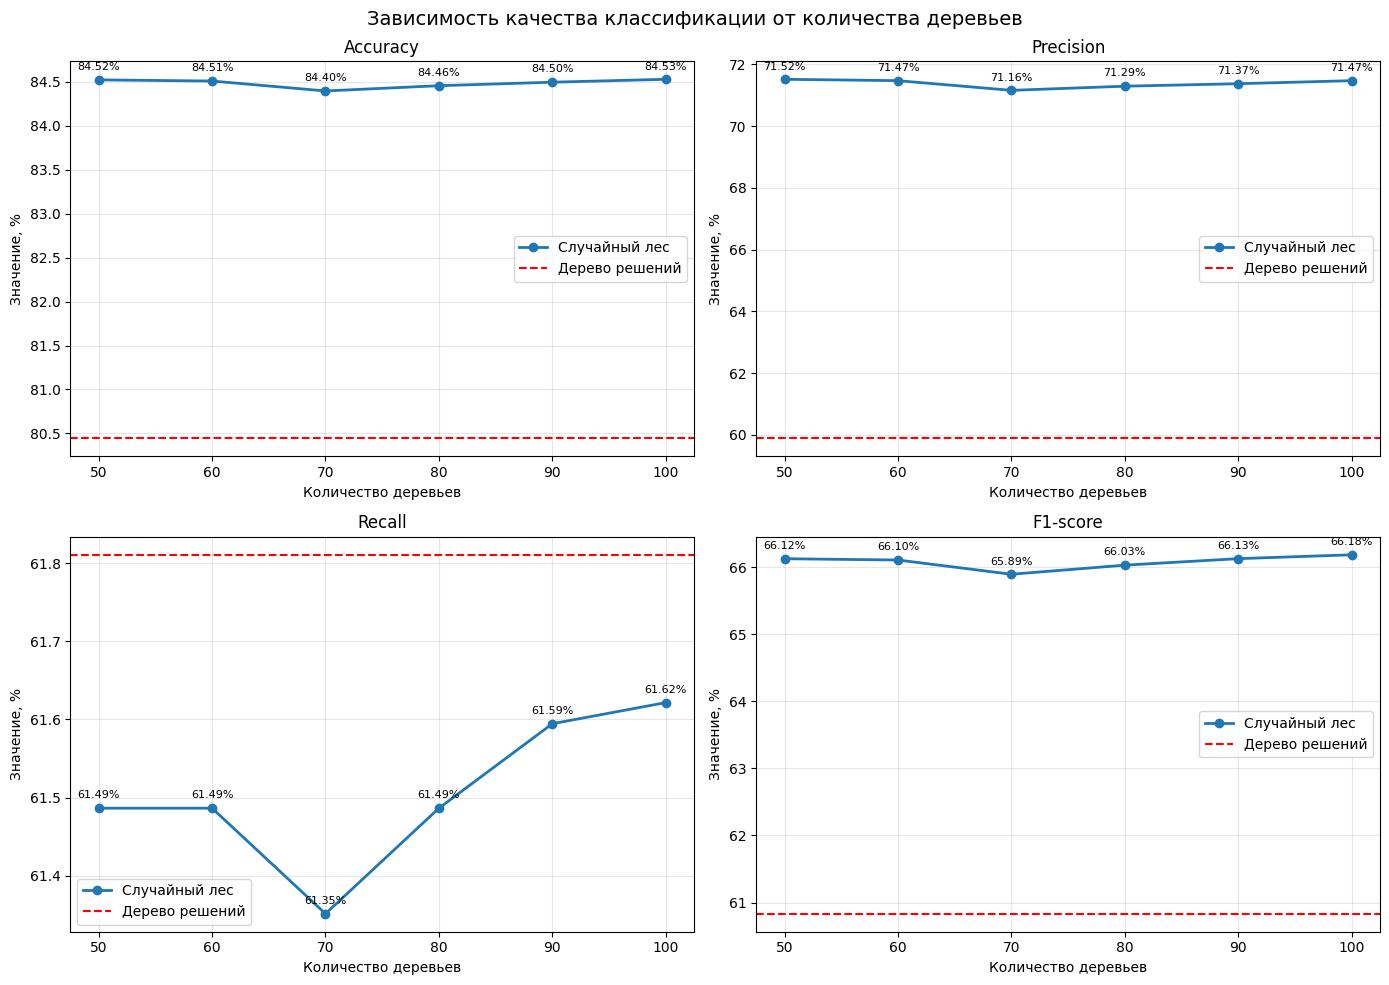

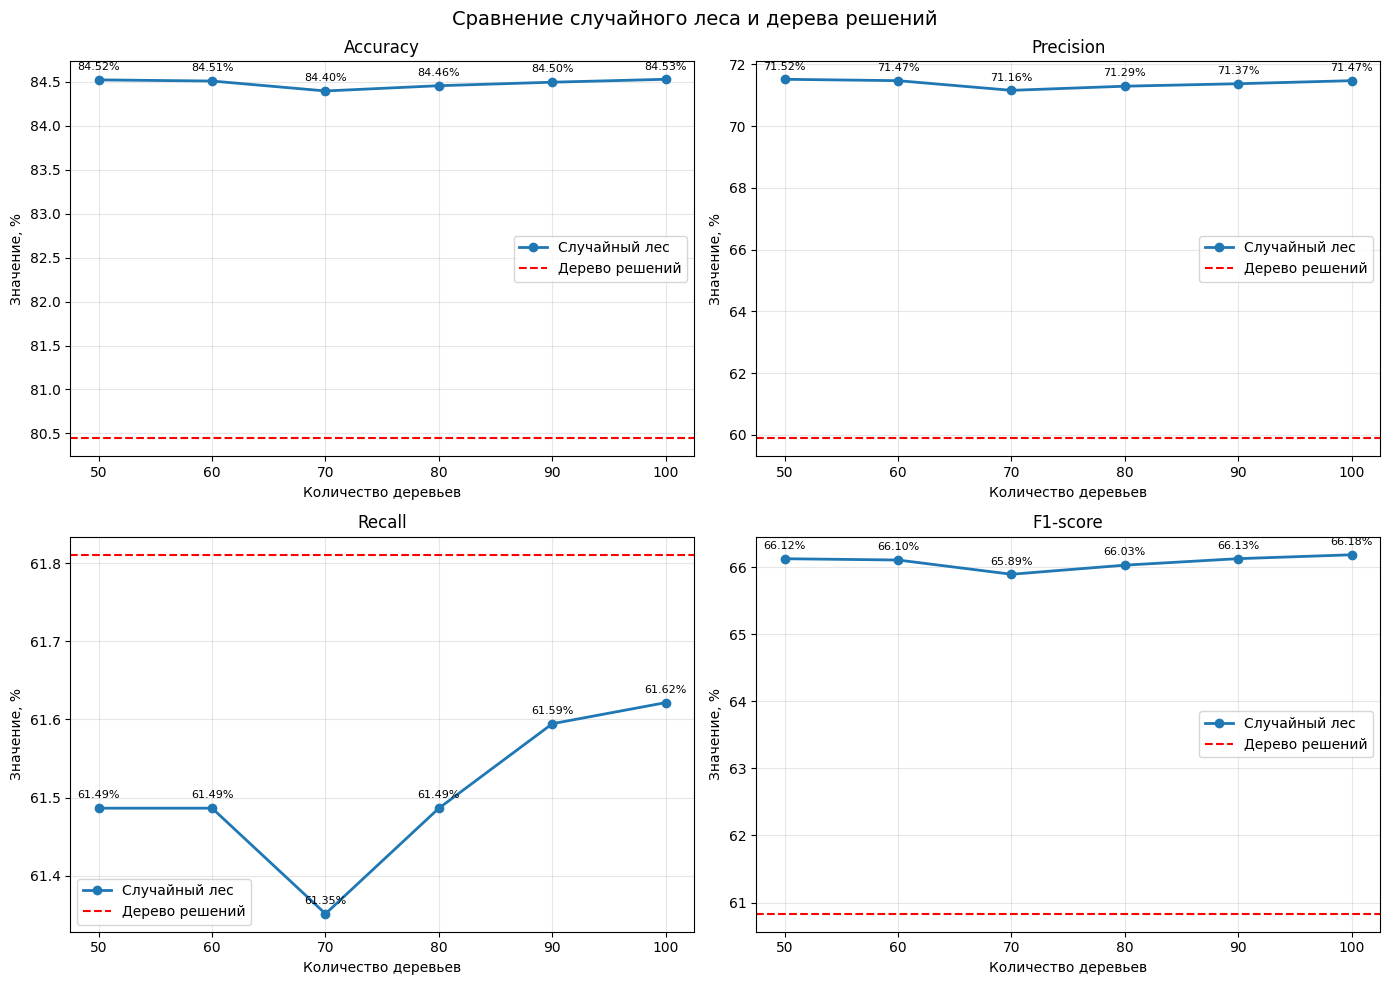

График сохранён в файл results_graphs.png
Таблица сохранена в results.csv
ЛУЧШИЕ РЕЗУЛЬТАТЫ
----------------------------------------
Максимальная Accuracy: 84.53%
Количество деревьев: 100

Максимальный F1-score: 66.18%
Количество деревьев: 100

Accuracy одиночного дерева: 80.44%
Разница с лучшим случайным лесом: 4.08 п.п.


In [7]:
metrics = {
    "Accuracy": tree_accuracy,
    "Precision": tree_precision,
    "Recall": tree_recall,
    "F1-score": tree_f1
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, metric in zip(axes.flatten(), metrics.keys()):
    values = results_df[metric] * 100

    # Результаты случайного леса
    ax.plot(
        results_df["Количество деревьев"],
        values,
        marker="o",
        linewidth=2,
        label="Случайный лес"
    )

    # Результат одиночного дерева
    ax.axhline(
        y=metrics[metric] * 100,
        color="red",
        linestyle="--",
        label="Дерево решений"
    )

    # Подписываем значения
    for x, y in zip(results_df["Количество деревьев"], values):
        ax.annotate(
            f"{y:.2f}%",
            (x, y),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=8
        )

    ax.set_title(metric)
    ax.set_xlabel("Количество деревьев")
    ax.set_ylabel("Значение, %")
    ax.set_xticks([50, 60, 70, 80, 90, 100])
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Зависимость качества классификации от количества деревьев",
    fontsize=14
)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, metric in zip(axes.flatten(), metrics.keys()):
    values = results_df[metric] * 100

    ax.plot(
        results_df["Количество деревьев"],
        values,
        marker="o",
        linewidth=2,
        label="Случайный лес"
    )

    ax.axhline(
        metrics[metric] * 100,
        color="red",
        linestyle="--",
        label="Дерево решений"
    )

    for x, y in zip(results_df["Количество деревьев"], values):
        ax.annotate(
            f"{y:.2f}%",
            (x, y),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=8
        )

    ax.set_title(metric)
    ax.set_xlabel("Количество деревьев")
    ax.set_ylabel("Значение, %")
    ax.set_xticks([50, 60, 70, 80, 90, 100])
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Сравнение случайного леса и дерева решений", fontsize=14)
plt.tight_layout()
plt.savefig("results_graphs.png", dpi=300, bbox_inches="tight")
plt.show()

print("График сохранён в файл results_graphs.png")

results_df.to_csv(
    "results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Таблица сохранена в results.csv")

best_accuracy = results_df.loc[
    results_df["Accuracy"].idxmax()
]

best_f1 = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("ЛУЧШИЕ РЕЗУЛЬТАТЫ")
print("-" * 40)

print(
    f"Максимальная Accuracy: "
    f"{best_accuracy['Accuracy']:.2%}"
)
print(
    f"Количество деревьев: "
    f"{int(best_accuracy['Количество деревьев'])}"
)

print(
    f"\nМаксимальный F1-score: "
    f"{best_f1['F1-score']:.2%}"
)
print(
    f"Количество деревьев: "
    f"{int(best_f1['Количество деревьев'])}"
)

print(f"\nAccuracy одиночного дерева: {tree_accuracy:.2%}")
print(
    f"Разница с лучшим случайным лесом: "
    f"{(best_accuracy['Accuracy'] - tree_accuracy) * 100:.2f} п.п."
)